In [2]:
import numpy as np
import torch
import os,glob
from collections import OrderedDict
from torchvision import datasets, transforms
from attrdict import AttrDict


from train_base import  (setup_randomness,
                         setup_dataset,
                         setup_model,
                         eval_trainedmodel,
                    )



#If you are sure your code is correct and simple want to get rid of this warning and all other warnings in the notebook do the following:

import warnings
warnings.filterwarnings('ignore')


import os
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"   # see issue #152
os.environ["CUDA_VISIBLE_DEVICES"]="0"

In [3]:
#trainset,contexset='cifar10', 'cifar100'
#trainset,contexset='cifar10', 'monochrome'

#trainset='cifar10'

# trainset,contexset='fmnist', 'kmnist'
# results_path = './results/final_{}_{}'.format(trainset,contexset)
# results_path_list = sorted(glob.glob(results_path + '/*'),reverse=True)

# trainset,contexset='fmnist', 'monochrome'
# results_path = './results/final_{}_{}'.format(trainset,contexset)
#results_path_list = sorted(glob.glob(results_path + '/*'),reverse=True)

trainset,contexset='cifar10', 'cifar100'
results_path = './results/{}_{}'.format(trainset,contexset)
#results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v67'))
#results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v68'))
#results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v69'))
#results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v70'))
results_path_list = sorted(glob.glob(results_path + '/*_nexp1_v90'))


#trainset,contexset='cifar10', 'cifar100'
# results_path = './results/final_{}_{}'.format(trainset,contexset)
# results_path_list = sorted(glob.glob(results_path + '/*'),reverse=True)


# trainset,contexset='cifar100', 'cifar10'
# results_path = './results/{}_{}_vessel'.format(trainset,contexset)
# results_path_list = sorted(glob.glob(results_path + '/*'),reverse=True)




In [4]:
results_path_list_reordered = []
# delete empty path
results_path_list_ = []
for ith_path in results_path_list:
    if len(glob.glob(ith_path + '/*')) > 0:
        results_path_list_.append(ith_path)        
results_path_list = results_path_list_

#results_path_list.sort(key=os.path.getmtime,reverse=True)
results_path_list.sort(key=os.path.getmtime)

results_path_list
 

['./results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample20_nepochratio0.9_nexp1_v90',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample50_nepochratio0.9_nexp1_v90',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v90',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd5resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample20_nepochratio0.9_nexp1_v90',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd5resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample50_nepochratio0.9_nexp1_v90',
 './

In [17]:
results_path_list_reordered = [
  './results/final_cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameresnet20_scalelogstd-4_nepoch250_nbatch128_lr0.1_Tmax250_nctset0_reglambda0.001_nfsample1_nexp3_v5',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrp2resnet20_scalelogstd-4_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.001_userelregFalse_nfsample200_updateperiod1_nexp1_v79',
#   './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample20_nepochratio0.9_nexp1_v88',  
#   './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample50_nepochratio0.9_nexp1_v88',  
  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v88',  
  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v90',
#  './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd5resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v90',
]


In [18]:
if len(results_path_list_reordered) == 0:
    results_path_list_reordered = results_path_list
    print('results_path_list_reordered is empty, using results_path_list')
results_path_list_reordered

['./results/final_cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameresnet20_scalelogstd-4_nepoch250_nbatch128_lr0.1_Tmax250_nctset0_reglambda0.001_nfsample1_nexp3_v5',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v88',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v90']

In [19]:
# #current_path_list
# #current_path in 
# idx=-1
# current_path = results_path_list[idx]
# current_path_list = sorted(glob.glob(current_path + '/*.pth'),reverse=True)    
# current_path_list

results_path_list_reordered



['./results/final_cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameresnet20_scalelogstd-4_nepoch250_nbatch128_lr0.1_Tmax250_nctset0_reglambda0.001_nfsample1_nexp3_v5',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v88',
 './results/cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnamefbrpcd4resnet20_scalelogstd-4_betahyp0.1_nepoch250_nbatch128_lr0.1_Tmax250_reglambda0.0_nfsample100_nepochratio0.9_nexp1_v90']

### figure together

In [20]:
from evaluate_v2 import (ts,
                         apply_t,
                         get_acc,
                         get_ll,
                         get_ece,
                         get_ood_auroc,           
                         get_entropy,              
                         )

from torch.nn.functional import log_softmax
from sklearn.model_selection import KFold
from scipy.optimize import minimize
from collections import OrderedDict

from datasets_v2 import make_randommonochrome_xc

# ## make random monochrome            
# if configs.dataset.contextset == 'monochrome':
#     xc = make_randommonochrome2_xc(xc)




def eval_trainedmodel(dataloader, model,q_params = None , nfsample=1, configs=None, datatype='x'):
    assert q_params is not None
    pred_list,label_list = [],[]    
    stdfs_list = []
    logits_list = []
    indist_list = []
    mhdist_list = []
    pseudolabel_list, pseudolabelp_list = [],[]
    model.eval()    
    with torch.no_grad():
        for i, (x, y) in enumerate(dataloader):    
            
            
            # if configs.dataset.contextset == 'monochrome' and datatype == 'xc':
            #     x = make_randommonochrome_xc(x)
                        
            # predict class            
            outs = model.predict_eval(x.cuda(), nfsample=nfsample)      
            # print('outs.keys(): {}'.format(outs.keys()))
            # print('outs.mh_distance: {}'.format(outs.mh_distance))

            # compute performance
            pred_list.append(outs.pred.cpu())
            label_list.append(y.cpu() )
            #logits_list.append(outs.logits.cpu())            
            if 'stdfs' in outs.keys():
                #stdfs_list.append(outs.stdfs.cpu())
                stdfs_list.append(outs.stdfs.cpu())
            if 'indist_score' in outs.keys():
               indist_list.append(outs.indist_score.cpu())
            if 'mh_distance' in outs.keys():
               mhdist_list.append(outs.mh_distance.cpu())               
            if 'pseudo_label' in outs.keys():                
               #pseudolabel_list.append(outs.pseudo_label.cpu())
               pseudolabel_list.append(outs.pseudo_label.cpu())               
            if 'pseudo_labelp' in outs.keys():                
               pseudolabelp_list.append(outs.pseudo_labelp.cpu())
               
            #     pass
            torch.cuda.empty_cache() 
            #rint(outs.logits.cpu())
    
    pred_list = torch.cat(pred_list,dim=0)    
    label_list = torch.cat(label_list,dim=0)
    if len(stdfs_list) > 0:    
        stdfs_list = torch.cat(stdfs_list,dim=0)        
    if len(indist_list) > 0:    
        indist_list = torch.cat(indist_list,dim=0)    
    if len(mhdist_list) > 0:
        mhdist_list = torch.cat(mhdist_list,dim=0)
    if len(pseudolabel_list) > 0:
        pseudolabel_list = torch.cat(pseudolabel_list,dim=0)
    if len(pseudolabelp_list) > 0:        
        pseudolabelp_list = torch.cat(pseudolabelp_list,dim=0)
        
    #print('logits_list.shape:{}'.format(logits_list.shape))
    # evaluate model
    outs = AttrDict()
    outs.pred_list = pred_list
    outs.label_list = label_list    
    outs.stdfs_list = stdfs_list
    outs.logits_list = logits_list
    outs.indist_list = indist_list
    outs.mhdist_list = mhdist_list
    outs.pseudolabel_list = pseudolabel_list    
    outs.pseudolabelp_list = pseudolabelp_list        
    return outs    



import copy
def update_keys_oddset(configs:AttrDict,ood_dict:dict):
    outs = {**dict(configs.dataset) , **ood_dict}
    configs.dataset = {}
    configs.dataset = AttrDict(outs)
    return copy.deepcopy(configs)



def compute_calibrated_performance(log_ood_preds,targets_ood, n_runs= 5,n_splits=2,digits=3):
    acc_runs,nll_runs,ece_runs,aucroc1,aucroc2 = [],[],[],[],[]
    for runs in range(n_runs):
        for i, (tr_idx, te_idx) in enumerate(KFold(n_splits=n_splits, shuffle=True).split(log_ood_preds)):
            train_t = ts(log_ood_preds[tr_idx], targets_ood[tr_idx])
            test_lp = apply_t(log_ood_preds[te_idx], train_t)                    
            acc_runs.append( get_acc(np.exp(test_lp), targets_ood[te_idx] ) )
            nll_runs.append( -get_ll(np.exp(test_lp), targets_ood[te_idx]) )
            ece_runs.append( get_ece(np.exp(test_lp), targets_ood[te_idx]) )       
        #aucroc1 = evaluate_aucroc(testloader, oodloader_v1, eval_trainedmodel, model, list(model.parameters()) , thresholds=100)
        #aucroc2 = evaluate_aucroc(testloader, oodloader_v2, eval_trainedmodel, model, list(model.parameters()) , thresholds=100)

    acc,nll,ece = np.mean(acc_runs).round(digits),np.mean(nll_runs).round(digits),np.mean(ece_runs).round(digits)                                   
    return acc,nll,ece


In [21]:
#i_th_saved['configs'].exp.seeds 
from datasets_v3 import corruptions, _setup_cifar10_c
c_type = corruptions[0]
batch_size=128


c_type, batch_size


('gaussian_noise', 128)

In [22]:
tesloader_c_list = [_setup_cifar10_c (c_type, c_level , batch_size) for c_level in range(0, 5+1) ]
tesloader_c_list

Files already downloaded and verified


In [23]:
#from evaluate_v2 import get_entropy2

## https://github.com/hendrycks/robustness/blob/master/ImageNet-C/create_c/make_cifar_c.py
result_dict = OrderedDict()
for current_path in results_path_list_reordered:
    #current_path_list = sorted(glob.glob(current_path + '/*.pth'),reverse=True) 
    current_path_list = sorted(glob.glob(current_path + '/*.pth'),reverse=False)       
    if len(current_path_list) == 0:
        break

    #c_oodloader = tesloader_c_list[0]
    for c_oodloader in tesloader_c_list:

        acc_list,nll_list,ece_list = [],[],[]
        for i_th_file in current_path_list:
            print('-'*150)
            print('filename: {}'.format(i_th_file))
            i_th_saved = torch.load(i_th_file)     

            ## setup randomness
            print('seeds: {}'.format(i_th_saved['configs'].exp.seeds))           
            setup_randomness(i_th_saved['configs'].exp.seeds)
                                
            ## setup model                        
            model,optimizer,scheduler = setup_model(i_th_saved['configs'])

            ## load params
            model.load_state_dict(i_th_saved['state_dict'])
            if hasattr(model,'static_mh'):
                model.static_mh.set_usemhbias()

            ## evaluate model
            nfsample     =   i_th_saved['configs'].train.nfsample
            outs_ood     =   eval_trainedmodel(c_oodloader, 
                                               model, 
                                               q_params = list(model.parameters()),
                                               nfsample = nfsample,
                                               datatype='xo')       
            
            log_ood_preds, targets_ood = outs_ood.pred_list.log().cpu().data.numpy(), outs_ood.label_list.cpu().data.numpy() 
            acc,nll,ece = compute_calibrated_performance(log_ood_preds,targets_ood)

            acc_list.append(acc)
            nll_list.append(nll)
            ece_list.append(ece)        
                
        acc_s = np.mean(acc_list).round(3),  np.std(acc_list).round(3)        
        nll_s = np.mean(nll_list).round(3),  np.std(nll_list).round(3)        
        ece_s = np.mean(ece_list).round(3),  np.std(ece_list).round(3)        
            
            
        # result_dict[dictname] = (ent_train,ent_test,ent_context,ent_ood,ent_ood1e4)
        dictname = i_th_saved['configs'].model.modelname
        dictname += i_th_file.split('/')[-1][-16:-4]            
        
        if dictname not in result_dict.keys():        
            result_dict[dictname] = { 'result_acc': [  (acc_s) ],
                                       'result_nll': [ (nll_s) ],
                                       'result_ece': [ (ece_s) ],
                                      'config': i_th_saved['configs'],
                                    }
        else:
            result_dict[dictname]['result_acc'].append((acc_s))
            result_dict[dictname]['result_nll'].append((nll_s))
            result_dict[dictname]['result_ece'].append((ece_s))
            

        


------------------------------------------------------------------------------------------------------------------------------------------------------
filename: ./results/final_cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameresnet20_scalelogstd-4_nepoch250_nbatch128_lr0.1_Tmax250_nctset0_reglambda0.001_nfsample1_nexp3_v5/seeds1111_gentime04281737.pth
seeds: 1111
get deep model: resnet20
------------------------------------------------------------------------------------------------------------------------------------------------------
filename: ./results/final_cifar10_cifar100/trainsetcifar10_contextsetcifar100_modelnameresnet20_scalelogstd-4_nepoch250_nbatch128_lr0.1_Tmax250_nctset0_reglambda0.001_nfsample1_nexp3_v5/seeds1112_gentime04281737.pth
seeds: 1112
get deep model: resnet20
------------------------------------------------------------------------------------------------------------------------------------------------------
filename: ./results/final_cifar10_cifar10

In [24]:
#result_dict['resnet20time04281737']['result_acc']



In [25]:
#results

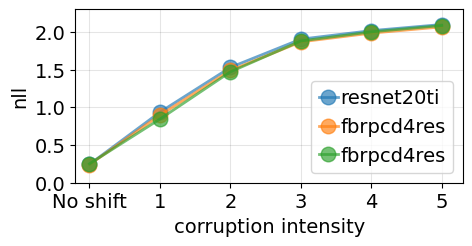

In [32]:
from attrdict import AttrDict
import matplotlib.pyplot as plt
import matplotlib 

from evaluate_v2 import get_entropy2
from attrdict import AttrDict

#nsubfig=3
nsubfig=4
nsubfig2=4
config_figs = AttrDict()
#config_figs.figsiz = (4.5,3)
#config_figs.figsiz = (nsubfig*4.5,3)
#config_figs.figsiz = (nsubfig*4.5,nsubfig2*3)
#config_figs.figsiz = (nsubfig*4.5,nsubfig2*4)
#config_figs.figsiz = (5,3)
config_figs.figsiz = (5,2.25)

# config_figs.nbins =100
# eps=1e-2
# config_figs.xlim = [0 - eps,2 + eps] 
# config_figs.xticks = [0,1,2]
# config_figs.ylim = [0,3] 
# config_figs.yticks = [1,2,3]
# config_figs.xlim2 = [0.0 - eps,1 + eps] 
# config_figs.xticks2 = [0.2,0.4,0.6,0.8,1]

# config_figs.ylim2 = [0 -eps , 10+eps] 
# config_figs.yticks2 = [2,4,6,8,10]

# config_figs.xticks = [0,5] 
# config_figs.yticks = [0,5] 
config_figs.fontsiz = 14
config_figs.fontsiztitle = 12
#config_figs.alpha= 0.33
#config_figs.alpha= 0.66
config_figs.alpha= 0.66
config_figs.alpha2= 0.33


matplotlib.rc('xtick', labelsize=config_figs.fontsiz) 
matplotlib.rc('ytick', labelsize=config_figs.fontsiz) 
matplotlib.rc('axes',  labelsize=config_figs.fontsiz) 


    
eps=2e-1   
config_figs.nbins =100
config_figs.xlim = [0 - eps,5.1 + eps] 
config_figs.xticks = ['No shift','1','2','3','4','5']
config_figs.ylim = [0.0,2.3] 
config_figs.yticks = [.0,.5,1.,1.5,2.0]
config_figs.range = [0-eps,2 +eps]
config_figs.range2 = [0-eps,1 +eps]

# config_figs.xlim2 = [0.0 - eps,1 + eps] 
# config_figs.xticks2 = [0.3,0.6,0.9]
# #config_figs.xlim2 = [0.8- eps,1 + eps] 
# #config_figs.xticks2 = [0.8,0.9,1]

# config_figs.ylim2 = [0 -eps , 10+eps] 
# config_figs.yticks2 = [2,4,6,8,10]

# config_figs.range = [0-eps,2 +eps]
# config_figs.range2 = [0-eps,1 +eps]


## nll
f,axs= plt.subplots(  figsize=config_figs.figsiz )    
for ith_key in result_dict:                
    #results = result_dict['resnet20time04281737']['result_acc']
    results = result_dict[ith_key]['result_nll']
    results = np.array(results)
    
    mu,std  = results[:,0],results[:,1]
    xrange = np.arange(len(mu))    
    axs.plot(xrange,
            mu  , 
            linestyle = '-',
            linewidth = 2.0,
            marker = 'o',
            markersize = 10.5,
            alpha = config_figs.alpha,
            label=ith_key[:10])  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
                    
            
    # #axs.hist(result_dict[ith_key]['result'][0]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='train')  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
    # axs.hist(result_dict[ith_key]['result'][1]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='test')  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
    # axs.hist(result_dict[ith_key]['result'][2]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='context')  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
    # axs.hist(result_dict[ith_key]['result'][3]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='ood')  # arguments are passed to np.histogram

    #axs.set_xticks(config_figs.xticks)
    axs.set_xticks(xrange,config_figs.xticks)    
    axs.set_yticks(config_figs.yticks)
    axs.set_xlim(config_figs.xlim)
    axs.set_ylim(config_figs.ylim)

    axs.set_xlabel('corruption intensity',fontsize=config_figs.fontsiz)
    axs.set_ylabel('nll',fontsize=config_figs.fontsiz)
    #axs[0,0].legend(loc='upper center',fontsize=config_figs.fontsiz,ncol=2,columnspacing=1.0,handlelength=1.0,handletextpad=.1 )
    #axs.legend(loc='best',fontsize=config_figs.fontsiz,ncol=1,columnspacing=1.0,handlelength=1.0,handletextpad=.1 )
    axs.legend(loc='best',fontsize=config_figs.fontsiz,ncol=1,columnspacing=1.0,handlelength=1.0,handletextpad=.1 )
    axs.grid(alpha=0.1,color="black")



#     configs= result_dict[ith_key]['config']
#     savefigname  = configs.dataset.trainset + '_' + configs.dataset.contextset + '_'  + oodset_now
#     savedir = './figs/{}/'.format(savefigname)
#     if not os.path.exists(savedir):
#         os.makedirs(savedir)
#     savefigname += '_' + configs.model.modelname + '_' + 'nfs{}'.format(configs.train.nfsample)

#     # if 'targetacc' in i_th_saved['configs'].train.keys():
#     #     savefigname += '_tacc{}'.format(i_th_saved['configs'].train.targetacc)
#     # if 'priorstdout' in i_th_saved['configs'].model.keys():
#     #     savefigname += '_pstdin{}_pstdout{}'.format(i_th_saved['configs'].model.priorstdin,i_th_saved['configs'].model.priorstdout)
#     # #savefigname += '_predentindist'                
#     savefigname += '_seeds{}'.format(configs.exp.seeds)
#     savefig_dir_name = savedir + savefigname  + '.pdf'
#     #plt.savefig(savefig_dir_name  , format='pdf', dpi=1000, bbox_inches='tight')        
#     plt.show()
#     print('current saved name: {}'.format(savefig_dir_name))





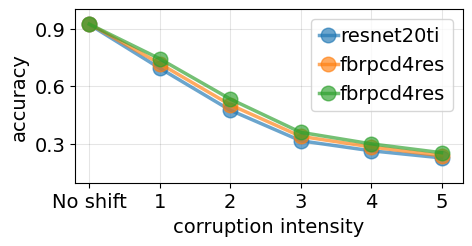

In [33]:
## acc


#nsubfig=3
nsubfig=4
nsubfig2=4
config_figs = AttrDict()
#config_figs.figsiz = (4.5,3)
#config_figs.figsiz = (nsubfig*4.5,3)
#config_figs.figsiz = (nsubfig*4.5,nsubfig2*3)
#config_figs.figsiz = (nsubfig*4.5,nsubfig2*4)
#config_figs.figsiz = (5,3)
config_figs.figsiz = (5,2.25)

config_figs.nbins =100
eps=1e-2
# config_figs.xticks = [0,5] 
# config_figs.yticks = [0,5] 
config_figs.fontsiz = 14
config_figs.fontsiztitle = 12
#config_figs.alpha= 0.33
#config_figs.alpha= 0.66
config_figs.alpha= 0.66
config_figs.alpha2= 0.33
config_figs.range = [0-eps,2 +eps]
config_figs.range2 = [0-eps,1 +eps]


matplotlib.rc('xtick', labelsize=config_figs.fontsiz) 
matplotlib.rc('ytick', labelsize=config_figs.fontsiz) 
matplotlib.rc('axes',  labelsize=config_figs.fontsiz) 

    
eps=2e-1   
config_figs.xlim = [0 - eps,5.1 + eps] 
config_figs.xticks = ['No shift','1','2','3','4','5']
config_figs.ylim = [0.1,1] 
config_figs.yticks = [.3,.6,.9]



f,axs= plt.subplots(  figsize=config_figs.figsiz )    
for ith_key in result_dict:                
    #results = result_dict['resnet20time04281737']['result_acc']
    results = result_dict[ith_key]['result_acc']
    results = np.array(results)    
    mu,std  = results[:,0],results[:,1]
    xrange = np.arange(len(mu))        
    axs.plot(xrange,
            mu  , 
            linestyle = '-',
            linewidth = 2.5,
            marker = 'o',
            markersize = 10.5,
            alpha = config_figs.alpha,
            label=ith_key[:10])  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
                    
            
    # #axs.hist(result_dict[ith_key]['result'][0]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='train')  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
    # axs.hist(result_dict[ith_key]['result'][1]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='test')  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
    # axs.hist(result_dict[ith_key]['result'][2]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='context')  # arguments are passed to np.histogramplt.legend(loc='upper right',fontsize=15)
    # axs.hist(result_dict[ith_key]['result'][3]    , density=True , bins=config_figs.nbins, alpha=config_figs.alpha  ,range =config_figs.range  ,label='ood')  # arguments are passed to np.histogram

    axs.set_xticks(xrange,config_figs.xticks)
    axs.set_yticks(config_figs.yticks)
    axs.set_xlim(config_figs.xlim)
    axs.set_ylim(config_figs.ylim)

    axs.set_xlabel('corruption intensity',fontsize=config_figs.fontsiz)
    axs.set_ylabel('accuracy',fontsize=config_figs.fontsiz)
    #axs[0,0].legend(loc='upper center',fontsize=config_figs.fontsiz,ncol=2,columnspacing=1.0,handlelength=1.0,handletextpad=.1 )
    #axs.legend(loc='best',fontsize=config_figs.fontsiz,ncol=1,columnspacing=1.0,handlelength=1.0,handletextpad=.1 )
    axs.legend(loc='best',fontsize=config_figs.fontsiz,ncol=1,columnspacing=1.0,handlelength=1.0,handletextpad=.1 )
    axs.grid(alpha=0.1,color="black")



#     configs= result_dict[ith_key]['config']
#     savefigname  = configs.dataset.trainset + '_' + configs.dataset.contextset + '_'  + oodset_now
#     savedir = './figs/{}/'.format(savefigname)
#     if not os.path.exists(savedir):
#         os.makedirs(savedir)
#     savefigname += '_' + configs.model.modelname + '_' + 'nfs{}'.format(configs.train.nfsample)

#     # if 'targetacc' in i_th_saved['configs'].train.keys():
#     #     savefigname += '_tacc{}'.format(i_th_saved['configs'].train.targetacc)
#     # if 'priorstdout' in i_th_saved['configs'].model.keys():
#     #     savefigname += '_pstdin{}_pstdout{}'.format(i_th_saved['configs'].model.priorstdin,i_th_saved['configs'].model.priorstdout)
#     # #savefigname += '_predentindist'                
#     savefigname += '_seeds{}'.format(configs.exp.seeds)
#     savefig_dir_name = savedir + savefigname  + '.pdf'
#     #plt.savefig(savefig_dir_name  , format='pdf', dpi=1000, bbox_inches='tight')        
#     plt.show()
#     print('current saved name: {}'.format(savefig_dir_name))
